# Part 1

> Two koi, Nemo and Dory, live in a pond that’s long and straight. All day long, they swim back and forth, over and over again. Nemo supposedly swims at a speed of exactly 1 mile per hour, while Dory swims faster at 2 miles per hour. That said, you design an experiment to measure their speeds.
>
> You place a sensor in the water that measures the speed of any passing fish and records the event in a log. You collect many such measurements over the course of several days, after which you read out the data and compute the average speed of all the events in the log.
>
> If indeed the fish’s speeds were 1 and 2 miles per hour, what average should you expect to get?


# Solution

Let $v_1$ and $v_2$ be the speeds of the fish and let our pond have unit length. Whenever a fish passes our sensor we record its speed. The key thing to realize here is that not only will the faster fish record a higher speed, it will also be recorded _more_ often, which will skew the average above the naive average.

Suppose we are recording the fish over a long time period $T \gg 1$. Let $n_i$ be the number of times we record fish $i$ in that time period. A round trip covers 2 units and passes the sensor twice (once in each direction), so a fish is recorded once per unit of distance traveled. In time $T$, fish $i$ travels $v_i T$ units, so we record it approximately $n_i = v_i T$ times.

Therefore, we expect the total number of measurements to be $n = n_1 + n_2$, and their average will be

$$
\begin{equation}
    \begin{aligned}
    \overline{v} & = \frac{v_1 n_1 + v_2 n_2}{n_1 + n_2}\\
                 & = \frac{v_1^2 + v_2^2}{v_1 + v_2}
    \end{aligned}
\end{equation}
$$

Plugging in our values of $v_1 = 1$ and $v_2 = 2$, we find
$$ \boxed{\overline{v} = \frac{5}{3}}.$$

As mentioned, this is slightly larger than the value you may initially guess of $3/2$.


# Part 2

> Another pond that’s also long and straight contains many, many koi. Initially, they’re all placed at the center of the pond, after which they all swim off at random velocities chosen from a normal distribution with a mean of 0 and a standard deviation of 1 mile per hour. A fish with a positive velocity initially swims toward one end of the pond, while a fish with a negative velocity initially swims toward the other end. The fish then swim back and forth, over and over again.
>
> As before, you place a sensor in the water that measures the speed of each passing fish. All speeds are recorded as positive; direction no longer matters. You collect many such measurements over the course of several days, after which you read out the data and compute the average speed the sensor detected.
>
> Toward what value will this average speed converge?


# Solution

We can leverage our intuition from Part 1. If we have $k$ fish with speeds $v_1, \ldots, v_k$, then over a long interval $T$, fish $i$ will be measured approximately $v_i T$ times.

Therefore the average measured speed will be

$$\overline{v} = \frac{v_1^2 + \ldots + v_k^2}{v_1 + \ldots + v_k}$$

This is for a known number of fish $k$ and known speeds $v_1, \ldots, v_k$. In our case the speeds are random: $V_i = |Z_i|$ with $Z_i$ i.i.d. $\mathcal{N}(0, 1)$, so the $V_i$ are i.i.d. with the [half-normal distribution](https://en.wikipedia.org/wiki/Half-normal_distribution). We want to find the limit of $\overline{v}$ as $k \to \infty$.

Before we do that analytically, let's simulate it and see if anything interesting shows up.


In [69]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")


def abs_standard_normal_RV(dim):
    X = np.abs(np.random.standard_normal(dim))
    return X


def get_trial_velocity(k):
    V = abs_standard_normal_RV(k)

    return np.sum(np.square(V)) / np.sum(V)

The estimate for k = 10000 fish is 1.2533


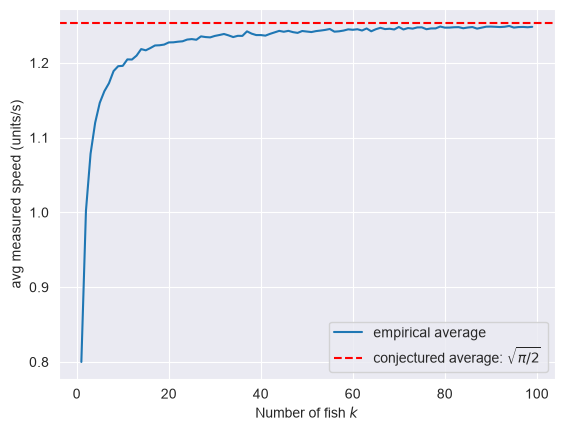

In [82]:
def simulate_avg_speed(k, num_trials=10_000):
    return sum(get_trial_velocity(k) for _ in range(num_trials)) / num_trials


print(
    f"The estimate for k = {10_000} fish is {simulate_avg_speed(10_000, num_trials=1_000_000):.4f}"
)
k_to_empirical_avg_speed = dict()
for k in range(1, 100):
    k_to_empirical_avg_speed[k] = simulate_avg_speed(k)


k_vals = k_to_empirical_avg_speed.keys()
avg_speeds = k_to_empirical_avg_speed.values()

plt.plot(k_vals, avg_speeds, label="empirical average")
plt.axhline(
    np.sqrt(np.pi / 2),
    color="red",
    linestyle="--",
    label=r"conjectured average: $\sqrt{\pi / 2}$",
)
plt.xlabel(r"Number of fish $k$")
plt.ylabel("avg measured speed (units/s)")
plt.legend()
plt.show()

Based on our plot and the large-$k$ example, the value seems to converge to `1.2533...`. If we use an [inverse symbolic calculator](https://thomasahle.com/ries/?T=1.2533), we see that this is suspiciously close to $\sqrt{\pi /2}$, which looks like the reciprocal of the constant in the density function of our half-normal distribution

$$
\begin{aligned}
f(v) &= 2 \frac{1}{\sqrt{2 \pi}}e^{-v^2/2}\quad \forall\; v\geq 0\\
    & = \sqrt{\frac{2}{\pi}}e^{-v^2/2}.
\end{aligned}
$$

The question is now can we show this analytically?

Specifically, we want to show that, [almost surely](https://en.wikipedia.org/wiki/Convergence_of_random_variables),

$$
\lim_{k \to \infty} \frac{V_1^2 + \ldots + V_k^2}{V_1 + \ldots + V_k} = \sqrt{\pi /2}.
$$

Start by considering the sequences $\overline{W}_k := \frac{1}{k}(V_1^2 + \ldots + V_k^2)$ and $\overline{V}_k := \frac{1}{k}(V_1 + \ldots + V_k)$. The $V_i$ are i.i.d., and so are the $V_i^2$, both with finite means, so by the [strong law of large numbers](https://en.wikipedia.org/wiki/Law_of_large_numbers), $\overline{V}_k \to \mu_V$ and $\overline{W}_k \to \mu_W$ almost surely as $k \to \infty$.

Doing some quick integration, we find that

$$
\begin{aligned}
\mu_V & = \int_0^\infty \sqrt{\frac{2}{\pi}}\; v \; e^{-v^2/2} dv = \sqrt{\frac{2}{\pi}}\\
\mu_W & = \int_0^\infty \sqrt{\frac{2}{\pi}}\; v^2 \;e^{-v^2/2} dv = 1
\end{aligned}
$$

Both limits hold simultaneously with probability 1 (this is the intersection of two probability-1 events), and on that event $\overline{V}_k \to \mu_V \neq 0$. So by the [limit law for quotients](https://web.ma.utexas.edu/users/m408s/AS/LM11-1-5.html), the sequence $a_k = \overline{W}_k / \overline{V}_k$ converges to the ratio of their limits:

$$\lim_{k \to \infty} \frac{\overline{W}_k}{\overline{V}_k} = \frac{\lim_{k \to \infty} \overline{W}_k }{\lim_{k \to \infty} \overline{V}_k } = \frac{1}{\sqrt{\frac{2}{\pi}}} = \boxed{\sqrt{\pi /2}}$$

which is the limit we expect from the simulation.


---